In [18]:
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
from aeon.visualisation import plot_critical_difference

In [19]:
def load_tsb_ad(
    mode: Literal["multivariate", "univariate"], return_characteristics: bool = False
) -> (pd.DataFrame, pd.DataFrame | None):
    mode_ = "uni" if mode == "univariate" else "multi"
    tsb_ad_raw_ = pd.read_csv(
        f"../results/TSB-AD/{mode_}_mergedTable_VUS-PR.csv", index_col="file"
    )
    tsb_ad_characteristics_cols_ = [
        "ts_len",
        "anomaly_len",
        "num_anomaly",
        "avg_anomaly_len",
        "anomaly_ratio",
        "point_anomaly",
        "seq_anomaly",
    ]
    tsb_ad_characteristics_ = tsb_ad_raw_[tsb_ad_characteristics_cols_]
    tsb_ad_ = tsb_ad_raw_.drop(columns=tsb_ad_characteristics_cols_)
    if return_characteristics:
        return tsb_ad_, tsb_ad_characteristics_
    else:
        return tsb_ad_


def load_results(
    method: str,
    mode: Literal["multivariate", "univariate"],
    return_runtime: bool = False,
) -> pd.DataFrame:
    results = pd.read_csv(f"../results/benchmarks/{method}-{mode}.csv")
    results = results.rename(columns={"VolumeUnderPR_TSBAD()": method})
    if return_runtime:
        return results[["file", "Runtime [s]"]].set_index("file")
    else:
        return results[["file", method]].set_index("file")


def load_with_tsb_ad(
    method: str, mode: Literal["multivariate", "univariate"]
) -> pd.DataFrame:
    tsb_ad_ = load_tsb_ad(mode=mode, return_characteristics=False)
    results_ = (
        load_results(method=method, mode=mode, return_runtime=False)
        .groupby("file")
        .mean()
    )
    return tsb_ad_.join(results_)

## Performances

In [20]:
def critical_difference_plot(
    df: pd.DataFrame,
    title: str = "",
    nb_methods: int = None,
    figsize=(12, 3),
) -> plt.Figure:
    if nb_methods is not None:
        df = df[df.mean().sort_values(ascending=False).index[:nb_methods]]

    fig, ax = plot_critical_difference(
        df.values, df.columns, return_p_values=False, highlight={"HydraAD": "red"}
    )
    ax.set_title(title, fontsize=16)
    fig.set_size_inches(*figsize)

    return fig

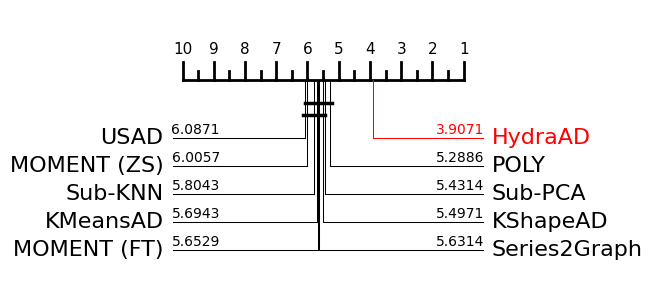

In [21]:
fig = critical_difference_plot(
    load_with_tsb_ad("HydraAD", mode="univariate"),
    # title=f"Critical difference diagram of top-10 methods on {benchmark_name} benchmark",
    nb_methods=10,
    figsize=(4.5, 2.8),
)
fig.savefig("figures/fig-cd-u-top10.png", bbox_inches="tight")

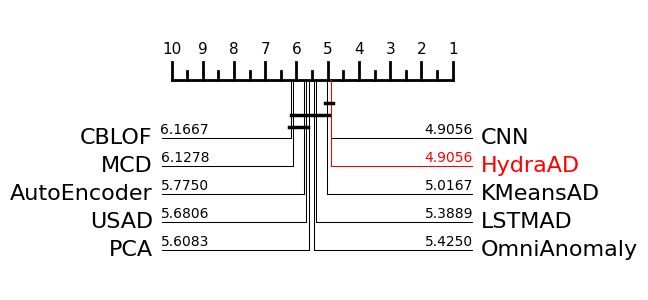

In [22]:
fig = critical_difference_plot(
    load_with_tsb_ad("HydraAD", mode="multivariate"),
    # title=f"Critical difference diagram of top-10 methods on {benchmark_name} benchmark",
    nb_methods=10,
    figsize=(4.5, 2.8),
)
fig.savefig("figures/fig-cd-m-top10.png", bbox_inches="tight")

## Run times

### Metadata

In [23]:
df = pd.read_csv(
    "../results/TSB-AD/reproduced/run_time_U/Sub-PCA.csv", index_col="file"
)
longest_u = df["Length"].idxmax().split("/")[1]
print(f"Longest univariate time series: {longest_u} of length {df['Length'].max()}")

Longest univariate time series: 331_UCR_id_29_Facility_tr_50000_1st_837400.csv of length 900000


In [35]:
df = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/CNN.csv", index_col="file")
longest_m = df["Length"].idxmax().split("/")[1]
print(
    f"Longest univariate time series: {longest_m} of length {df.loc[f'TSB-AD-M/{longest_m}', 'Length']} and dimension {df.loc[f'TSB-AD-M/{longest_m}', 'Dimension']}"
)

Longest univariate time series: 020_MITDB_id_2_Medical_tr_50000_1st_52315.csv of length 650000 and dimension 2


### HydraAD

In [39]:
device = "GPU"

In [40]:
df = pd.read_csv("../results/scalability/TSB-AD-U.csv", index_col="file")
df = df[df["Device"] == device]
print(f"Time on longest time series: {df.loc[longest_u]['Run time [s]']} seconds")
print(f"Total running time: {df['Run time [s]'].sum()} seconds")

Time on longest time series: 0.1968626976013183 seconds
Total running time: 7.458717823028547 seconds


In [41]:
df = pd.read_csv("../results/scalability/TSB-AD-M.csv", index_col="file")
df = df[df["Device"] == device]
print(f"Time on longest time series: {df.loc[longest_m]['Run time [s]']} seconds")
print(f"Total running time: {df['Run time [s]'].sum()} seconds")

Time on longest time series: 0.2303237915039062 seconds
Total running time: 32.05366230010986 seconds


### Univariate

In [28]:
df = pd.read_csv(
    "../results/TSB-AD/reproduced/run_time_U/Sub-PCA.csv", index_col="file"
)
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-U/{longest_u}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 11.3968691 seconds
Total running time: 429.8640736000001 seconds


In [29]:
df = pd.read_csv("../results/TSB-AD/reproduced/run_time_U/POLY.csv", index_col="file")
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-U/{longest_u}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 1.4252079 seconds
Total running time: 39.5690946 seconds


In [30]:
df = pd.read_csv(
    "../results/TSB-AD/reproduced/run_time_U/KShapeAD.csv", index_col="file"
)
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-U/{longest_u}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 278.3794555 seconds
Total running time: 8875.721055400001 seconds


### Multivariate

In [31]:
df = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/CNN.csv", index_col="file")
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-M/{longest_m}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 54.3223404 seconds
Total running time: 2220.2604563 seconds


In [32]:
df = pd.read_csv(
    "../results/TSB-AD/reproduced/run_time_M/KMeansAD.csv", index_col="file"
)
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-M/{longest_m}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 167.6641292 seconds
Total running time: 2961.7862136000003 seconds


In [33]:
df = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/LSTMAD.csv", index_col="file")
print(
    f"Time on longest time series: {df.loc[f'TSB-AD-M/{longest_m}']['Runtime [s]']} seconds"
)
print(f"Total running time: {df['Runtime [s]'].sum()} seconds")

Time on longest time series: 36.4717627 seconds
Total running time: 4938.8645094 seconds
